# 02 — Đặc trưng từ dữ liệu có thể đọc khi tiếp nhận

Chỉ dùng dữ liệu của **lần sạc liền trước** và **lần đo trở kháng gần nhất** — tương ứng tham số Phụ lục VII EU 2023/1542 (số chu kỳ, điện trở) và dữ liệu BMS ghi được. Không dùng dữ liệu xả (vì xả kiểm tra chính là phép đo tay tốn thời gian).

| Đặc trưng | Ý nghĩa |
|---|---|
| full_cycles | Số chu kỳ tương đương |
| cc_time_s | Thời gian sạc dòng không đổi đến 4,2 V |
| cv_time_s | Thời gian sạc áp không đổi đến khi dòng < 0,5 A |
| t_max_charge_c | Nhiệt độ cao nhất khi sạc |
| v_start_charge | Điện áp lúc bắt đầu sạc |
| re_ohm, rct_ohm | Điện trở điện phân và điện trở chuyển điện tích |

In [1]:
import sys, json
sys.path.insert(0, '..')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import soh_pipeline as S
plt.rcParams.update({'figure.figsize': (8, 4), 'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.color': '#e4e3df'})
COL = {'B0005': '#2a78d6', 'B0006': '#eb6834', 'B0007': '#1baf7a', 'B0018': '#6250d6'}
df = S.dataset()
df[S.FEATURES + ['soh']].corr()['soh'].drop('soh').round(2).sort_values()

full_cycles      -0.91
rct_ohm          -0.74
cv_time_s        -0.72
re_ohm           -0.67
v_start_charge   -0.63
t_max_charge_c   -0.08
cc_time_s         0.92
Name: soh, dtype: float64

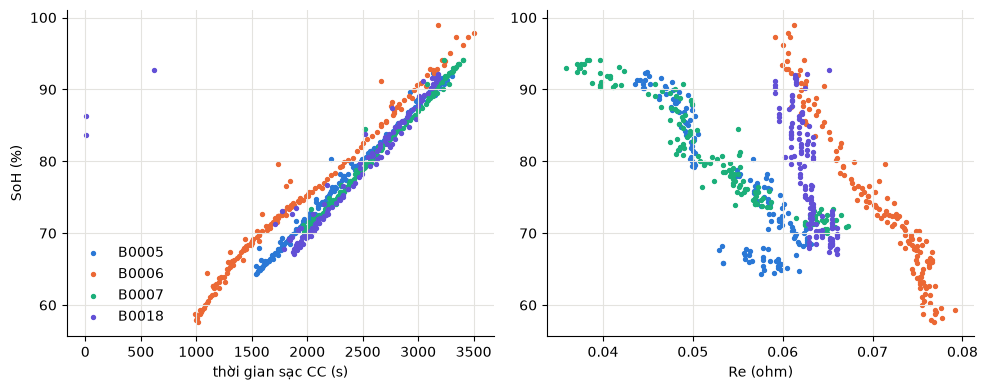

In [2]:
fig, axs = plt.subplots(1, 2, figsize=(10, 4))
for c, g in df.groupby('cell'):
    axs[0].scatter(g.cc_time_s, g.soh, s=8, color=COL[c], label=c)
    axs[1].scatter(g.re_ohm, g.soh, s=8, color=COL[c])
axs[0].set_xlabel('thời gian sạc CC (s)'); axs[1].set_xlabel('Re (ohm)'); axs[0].set_ylabel('SoH (%)'); axs[0].legend(frameon=False)
plt.tight_layout(); plt.show()

**Quan sát.** Thời gian sạc CC giảm khi pin già (pin chạm 4,2 V sớm hơn), tương quan mạnh với SoH. Điện trở tăng theo tuổi nhưng chỉ đo định kỳ, nên mang ít thông tin hơn.